In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("BusGuard Data Exploration")
print("Libraries loaded successfully!")

BusGuard Data Exploration
Libraries loaded successfully!


In [13]:
import pandas as pd
import numpy as np

# Initial BusGuard simulation data
data = {
    "condition": [
        "Healthy",
        "Healthy",
        "Healthy",
        "Near_Failure",
        "Near_Failure",
        "Near_Failure"
    ],
    
    "time_s": [
        32.17,
        33.17,
        34.18,
        0.00,
        1.00,
        2.00
    ],
    
    "current_mA": [
        33.90,
        33.90,
        33.90,
        4.37,
        4.37,
        4.37
    ],
    
    "Vjoint_V": [
        0.015,
        0.015,
        0.015,
        4.360,
        4.360,
        4.360
    ],
    
    "Rjoint_ohm": [
        0.4,
        0.4,
        0.4,
        998.2,
        998.2,
        998.2
    ],
    
    "T_sim_C": [
        28.10,
        28.10,
        28.10,
        28.00,
        28.01,
        28.01
    ]
}

df = pd.DataFrame(data)

df

,condition,time_s,current_mA,Vjoint_V,Rjoint_ohm,T_sim_C
0,Healthy,32.17,33.90,0.015,0.4,28.10
1,Healthy,33.17,33.90,0.015,0.4,28.10
2,Healthy,34.18,33.90,0.015,0.4,28.10
3,Near_Failure,0.00,4.37,4.360,998.2,28.00
4,Near_Failure,1.00,4.37,4.360,998.2,28.01
5,Near_Failure,2.00,4.37,4.360,998.2,28.01


In [14]:
# Convert current from mA to A
df["current_A"] = df["current_mA"] / 1000

# Calculate joint power loss
df["power_loss_W"] = (
    df["current_A"] ** 2 * df["Rjoint_ohm"]
)

df

,condition,time_s,current_mA,Vjoint_V,Rjoint_ohm,T_sim_C,current_A,power_loss_W
0,Healthy,32.17,33.90,0.015,0.4,28.10,0.03390,0.000460
1,Healthy,33.17,33.90,0.015,0.4,28.10,0.03390,0.000460
2,Healthy,34.18,33.90,0.015,0.4,28.10,0.03390,0.000460
3,Near_Failure,0.00,4.37,4.360,998.2,28.00,0.00437,0.019063
4,Near_Failure,1.00,4.37,4.360,998.2,28.01,0.00437,0.019063
5,Near_Failure,2.00,4.37,4.360,998.2,28.01,0.00437,0.019063


In [15]:
# Temperature rise above ambient
T_AMBIENT = 28.0

df["delta_T_C"] = df["T_sim_C"] - T_AMBIENT

df

,condition,time_s,current_mA,Vjoint_V,Rjoint_ohm,T_sim_C,current_A,power_loss_W,delta_T_C
0,Healthy,32.17,33.90,0.015,0.4,28.10,0.03390,0.000460,0.10
1,Healthy,33.17,33.90,0.015,0.4,28.10,0.03390,0.000460,0.10
2,Healthy,34.18,33.90,0.015,0.4,28.10,0.03390,0.000460,0.10
3,Near_Failure,0.00,4.37,4.360,998.2,28.00,0.00437,0.019063,0.00
4,Near_Failure,1.00,4.37,4.360,998.2,28.01,0.00437,0.019063,0.01
5,Near_Failure,2.00,4.37,4.360,998.2,28.01,0.00437,0.019063,0.01


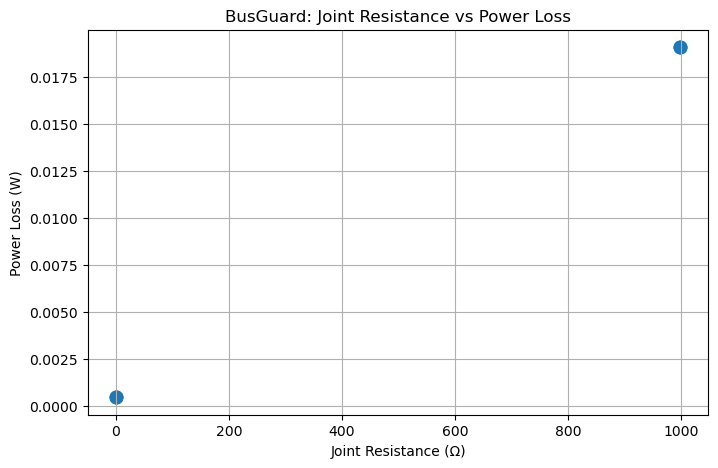

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Rjoint_ohm"],
    df["power_loss_W"],
    s=80
)

plt.xlabel("Joint Resistance (Ω)")
plt.ylabel("Power Loss (W)")
plt.title("BusGuard: Joint Resistance vs Power Loss")
plt.grid(True)

plt.show()

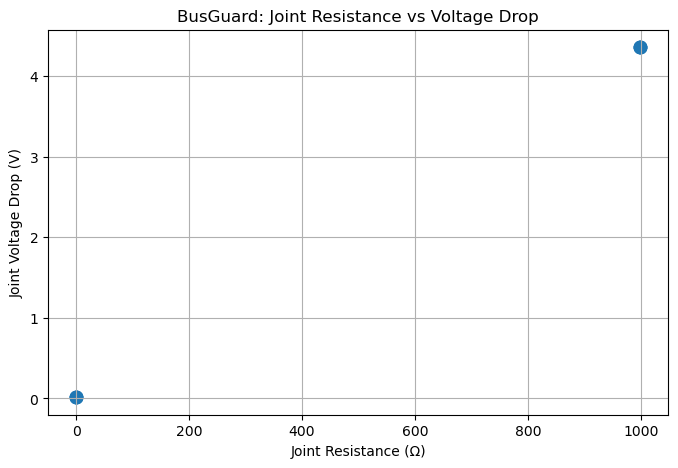

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Rjoint_ohm"],
    df["Vjoint_V"],
    s=80
)

plt.xlabel("Joint Resistance (Ω)")
plt.ylabel("Joint Voltage Drop (V)")
plt.title("BusGuard: Joint Resistance vs Voltage Drop")
plt.grid(True)

plt.show()

In [18]:
# Calculate additional BusGuard features

df["voltage_drop_power_check"] = (
    df["current_A"] * df["Rjoint_ohm"]
)

df["estimated_power_from_VI"] = (
    df["current_A"] * df["Vjoint_V"]
)

df["normalized_heating_index"] = (
    df["power_loss_W"] / df["current_A"].replace(0, np.nan)
)

df

,condition,time_s,current_mA,Vjoint_V,Rjoint_ohm,T_sim_C,current_A,power_loss_W,delta_T_C,voltage_drop_power_check,estimated_power_from_VI,normalized_heating_index
0,Healthy,32.17,33.90,0.015,0.4,28.10,0.03390,0.000460,0.10,0.013560,0.000508,0.013560
1,Healthy,33.17,33.90,0.015,0.4,28.10,0.03390,0.000460,0.10,0.013560,0.000508,0.013560
2,Healthy,34.18,33.90,0.015,0.4,28.10,0.03390,0.000460,0.10,0.013560,0.000508,0.013560
3,Near_Failure,0.00,4.37,4.360,998.2,28.00,0.00437,0.019063,0.00,4.362134,0.019053,4.362134
4,Near_Failure,1.00,4.37,4.360,998.2,28.01,0.00437,0.019063,0.01,4.362134,0.019053,4.362134
5,Near_Failure,2.00,4.37,4.360,998.2,28.01,0.00437,0.019063,0.01,4.362134,0.019053,4.362134


In [19]:
import json
import pandas as pd

def parse_serial_output(text, condition):
    rows = []

    for line in text.strip().splitlines():
        line = line.strip()

        if not line.startswith("{"):
            continue

        try:
            row = json.loads(line)
            row["condition"] = condition
            rows.append(row)
        except json.JSONDecodeError:
            pass

    return pd.DataFrame(rows)

In [26]:
from pathlib import Path

file_path = Path("../data/full_run.csv").resolve()

print(file_path)
print("Exists:", file_path.exists())
print("Size:", file_path.stat().st_size if file_path.exists() else "N/A")

C:\Users\priya\New folder\data\full_run.csv
Exists: True
Size: 4538


In [28]:
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (74, 11)


,t,tight,I,vdrop_mV,R_mohm,t_max,t_mean,t_amb,ac_100,ac_band,label
0,0.3,0.0,14.94,59.76,4.0,28.41,28.02,28.0,0.297,0.120,loose
1,1.6,0.0,14.87,59.48,4.0,28.53,28.03,28.0,0.275,0.123,loose
2,2.8,0.0,15.13,60.52,4.0,28.67,28.05,28.0,0.280,0.127,loose
3,4.0,0.0,14.80,59.20,4.0,28.74,28.05,28.0,0.272,0.112,loose
4,5.3,0.0,15.13,60.52,4.0,28.78,28.06,28.0,0.282,0.127,loose


In [29]:
print(df.columns.tolist())
print()
print(df.iloc[0].to_dict())

['t', 'tight', 'I', 'vdrop_mV', 'R_mohm', 't_max', 't_mean', 't_amb', 'ac_100', 'ac_band', 'label']

{'t': 0.3, 'tight': 0.0, 'I': 14.94, 'vdrop_mV': 59.76, 'R_mohm': 4.0, 't_max': 28.41, 't_mean': 28.02, 't_amb': 28.0, 'ac_100': 0.297, 'ac_band': 0.12, 'label': 'loose'}


In [30]:
print(file_path.read_text(encoding="utf-8-sig")[:1000])

t,tight,I,vdrop_mV,R_mohm,t_max,t_mean,t_amb,ac_100,ac_band,label
0.3,0.0,14.94,59.76,4.0,28.41,28.02,28.0,0.297,0.12,loose
1.6,0.0,14.87,59.48,4.0,28.53,28.03,28.0,0.275,0.123,loose
2.8,0.0,15.13,60.52,4.0,28.67,28.05,28.0,0.28,0.127,loose
4.0,0.0,14.8,59.2,4.0,28.74,28.05,28.0,0.272,0.112,loose
5.3,0.0,15.13,60.52,4.0,28.78,28.06,28.0,0.282,0.127,loose
6.5,0.0,14.94,59.76,4.0,28.87,28.08,28.0,0.295,0.124,loose
7.8,0.0,14.9,59.6,4.0,28.94,28.08,28.0,0.275,0.112,loose
9.0,0.0,14.88,59.52,4.0,29.0,28.09,28.0,0.273,0.127,loose
10.3,0.0,15.04,60.16,4.0,28.91,28.08,28.0,0.287,0.112,loose
11.5,0.07,15.1,56.89,3.77,29.08,28.1,28.0,0.277,0.105,loose
12.7,0.07,14.94,55.88,3.74,29.04,28.1,28.0,0.262,0.119,loose
14.0,0.12,15.1,53.95,3.57,29.11,28.1,28.0,0.253,0.1,loose
15.2,0.21,15.0,49.12,3.27,29.09,28.1,28.0,0.224,0.108,loose
16.5,0.23,14.86,47.29,3.18,29.01,28.1,28.0,0.225,0.097,loose
17.7,0.29,14.8,44.06,2.98,29.02,28.1,28.0,0.216,0.097,mid
19.0,0.42,14.93,37.66,2.52,29.0,28.09,28.0,0.169,0.

In [31]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nCondition counts:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Shape: (74, 11)

Columns:
['t', 'tight', 'I', 'vdrop_mV', 'R_mohm', 't_max', 't_mean', 't_amb', 'ac_100', 'ac_band', 'label']

Condition counts:
label
loose    27
mid      25
tight    22
Name: count, dtype: int64

Missing values:
t           0
tight       0
I           0
vdrop_mV    0
R_mohm      0
t_max       0
t_mean      0
t_amb       0
ac_100      0
ac_band     0
label       0
dtype: int64


In [32]:
df["delta_T"] = df["t_max"] - df["t_amb"]

df[[
    "label",
    "R_mohm",
    "vdrop_mV",
    "t_max",
    "delta_T",
    "ac_100",
    "ac_band"
]].head()

,label,R_mohm,vdrop_mV,t_max,delta_T,ac_100,ac_band
0,loose,4.0,59.76,28.41,0.41,0.297,0.120
1,loose,4.0,59.48,28.53,0.53,0.275,0.123
2,loose,4.0,60.52,28.67,0.67,0.280,0.127
3,loose,4.0,59.20,28.74,0.74,0.272,0.112
4,loose,4.0,60.52,28.78,0.78,0.282,0.127


In [34]:
summary = df.groupby("label").agg(
    samples=("label", "size"),
    current_A=("I", "mean"),
    resistance_mohm=("R_mohm", "mean"),
    voltage_drop_mV=("vdrop_mV", "mean"),
    max_temperature_C=("t_max", "mean"),
    delta_T_C=("delta_T", "mean"),
    acoustic_100=("ac_100", "mean"),
    acoustic_band=("ac_band", "mean")
)

summary.round(3)

,samples,current_A,resistance_mohm,voltage_drop_mV,max_temperature_C,delta_T_C,acoustic_100,acoustic_band
label,,,,,,,,
loose,27,14.989,3.909,58.589,28.916,0.916,0.277,0.117
mid,25,14.987,2.220,33.271,28.910,0.910,0.160,0.067
tight,22,15.045,0.698,10.501,28.667,0.667,0.048,0.027


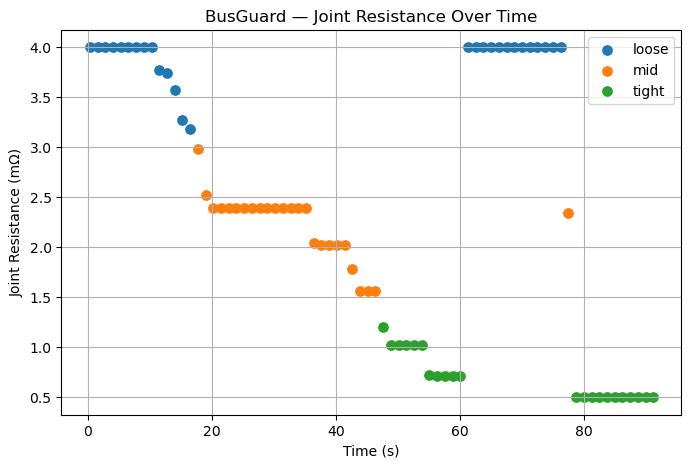

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for label, group in df.groupby("label"):
    plt.scatter(
        group["t"],
        group["R_mohm"],
        label=label,
        s=45
    )

plt.xlabel("Time (s)")
plt.ylabel("Joint Resistance (mΩ)")
plt.title("BusGuard — Joint Resistance Over Time")
plt.legend()
plt.grid(True)

plt.show()

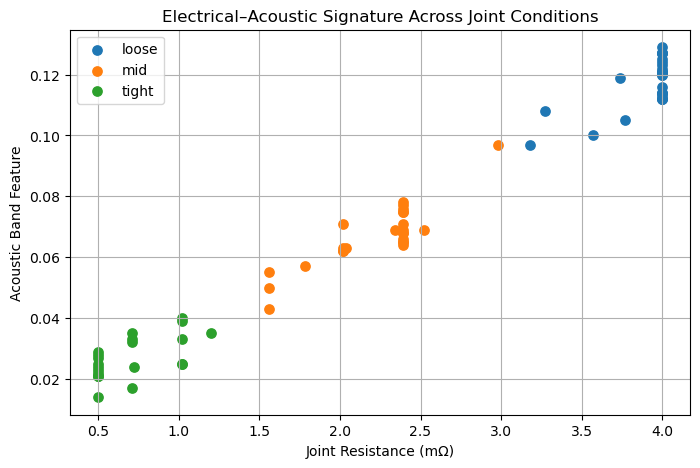

In [36]:
plt.figure(figsize=(8, 5))

for label, group in df.groupby("label"):
    plt.scatter(
        group["R_mohm"],
        group["ac_band"],
        label=label,
        s=45
    )

plt.xlabel("Joint Resistance (mΩ)")
plt.ylabel("Acoustic Band Feature")
plt.title("Electrical–Acoustic Signature Across Joint Conditions")
plt.legend()
plt.grid(True)

plt.show()

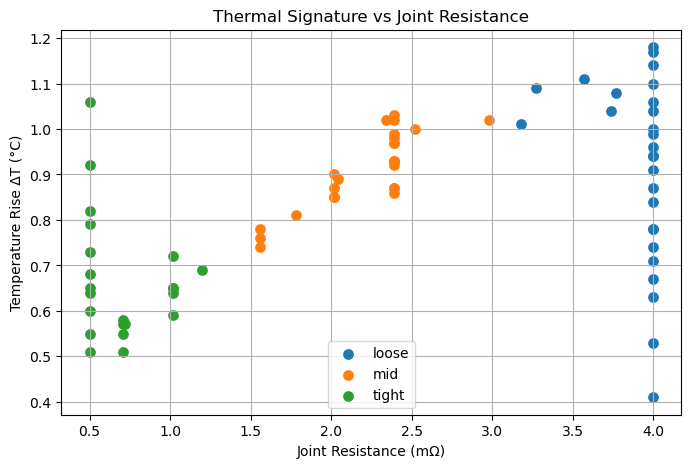

In [37]:
plt.figure(figsize=(8, 5))

for label, group in df.groupby("label"):
    plt.scatter(
        group["R_mohm"],
        group["delta_T"],
        label=label,
        s=45
    )

plt.xlabel("Joint Resistance (mΩ)")
plt.ylabel("Temperature Rise ΔT (°C)")
plt.title("Thermal Signature vs Joint Resistance")
plt.legend()
plt.grid(True)

plt.show()

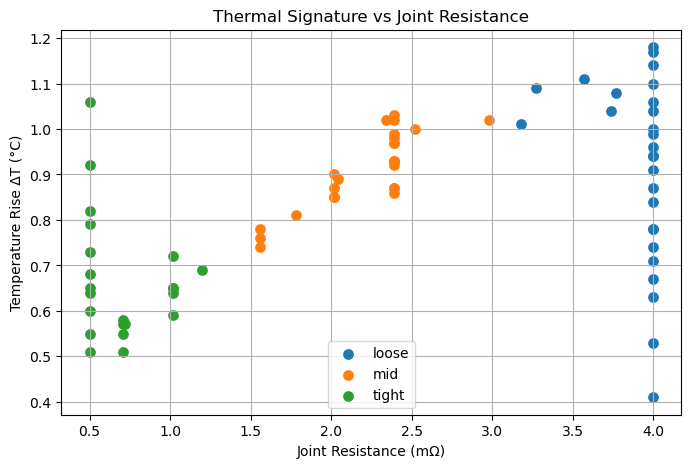

In [38]:
plt.figure(figsize=(8, 5))

for label, group in df.groupby("label"):
    plt.scatter(
        group["R_mohm"],
        group["delta_T"],
        label=label,
        s=45
    )

plt.xlabel("Joint Resistance (mΩ)")
plt.ylabel("Temperature Rise ΔT (°C)")
plt.title("Thermal Signature vs Joint Resistance")
plt.legend()
plt.grid(True)

plt.show()

In [39]:
summary = df.groupby("label").agg(
    samples=("label", "size"),
    current_A=("I", "mean"),
    resistance_mohm=("R_mohm", "mean"),
    voltage_drop_mV=("vdrop_mV", "mean"),
    max_temperature_C=("t_max", "mean"),
    delta_T_C=("delta_T", "mean"),
    acoustic_100=("ac_100", "mean"),
    acoustic_band=("ac_band", "mean")
)

summary.round(3)

,samples,current_A,resistance_mohm,voltage_drop_mV,max_temperature_C,delta_T_C,acoustic_100,acoustic_band
label,,,,,,,,
loose,27,14.989,3.909,58.589,28.916,0.916,0.277,0.117
mid,25,14.987,2.220,33.271,28.910,0.910,0.160,0.067
tight,22,15.045,0.698,10.501,28.667,0.667,0.048,0.027


In [40]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Features
electrical = ["I", "vdrop_mV", "R_mohm"]

thermal = ["t_max", "t_mean", "delta_T"]

acoustic = ["ac_100", "ac_band"]

electrical_thermal = electrical + thermal

sensor_fusion = electrical + thermal + acoustic

X = df
y = df["label"]

# Same train/test split for every model
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

feature_sets = {
    "Electrical": electrical,
    "Thermal": thermal,
    "Acoustic": acoustic,
    "Electrical + Thermal": electrical_thermal,
    "Full Sensor Fusion": sensor_fusion
}

results = []

for name, features in feature_sets.items():

    model = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        max_depth=5
    )

    model.fit(X_train[features], y_train)

    predictions = model.predict(X_test[features])

    accuracy = accuracy_score(y_test, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Electrical,1.000,1.000,1.000,1.000
1,Thermal,0.526,0.503,0.526,0.494
2,Acoustic,1.000,1.000,1.000,1.000
3,Electrical + Thermal,1.000,1.000,1.000,1.000
4,Full Sensor Fusion,1.000,1.000,1.000,1.000


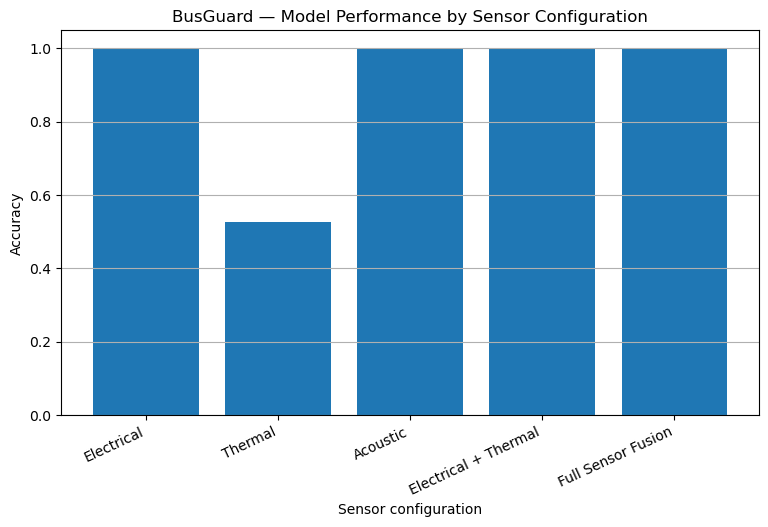

In [41]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Sensor configuration")
plt.title("BusGuard — Model Performance by Sensor Configuration")

plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1.05)
plt.grid(axis="y")

plt.show()

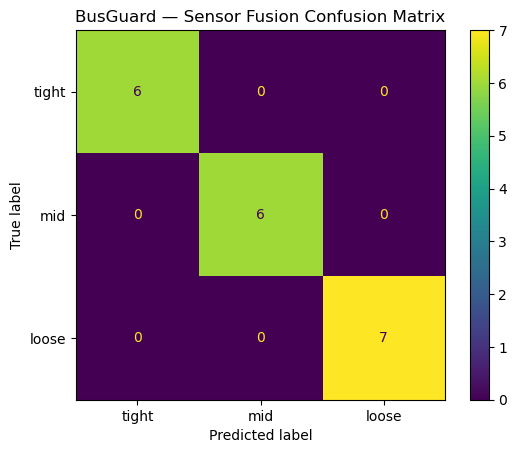

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Train final fusion model
fusion_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=5
)

fusion_model.fit(X_train[sensor_fusion], y_train)

fusion_predictions = fusion_model.predict(X_test[sensor_fusion])

cm = confusion_matrix(
    y_test,
    fusion_predictions,
    labels=["tight", "mid", "loose"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["tight", "mid", "loose"]
)

disp.plot()
plt.title("BusGuard — Sensor Fusion Confusion Matrix")
plt.show()

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Sort chronologically
df_sorted = df.sort_values("t").reset_index(drop=True)

features = [
    "I",
    "vdrop_mV",
    "R_mohm",
    "t_max",
    "t_mean",
    "delta_T",
    "ac_100",
    "ac_band"
]

# First 70% = training
# Last 30% = testing
split_index = int(len(df_sorted) * 0.70)

train = df_sorted.iloc[:split_index]
test = df_sorted.iloc[split_index:]

X_train = train[features]
y_train = train["label"]

X_test = test[features]
y_test = test["label"]

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("Time-aware test accuracy:", round(accuracy, 3))
print()
print(classification_report(y_test, predictions))

Time-aware test accuracy: 1.0

              precision    recall  f1-score   support

       loose       1.00      1.00      1.00        11
         mid       1.00      1.00      1.00         1
       tight       1.00      1.00      1.00        11

    accuracy                           1.00        23
   macro avg       1.00      1.00      1.00        23
weighted avg       1.00      1.00      1.00        23



In [44]:
print("Overall:")
print(df_sorted["label"].value_counts())

print("\nTraining set:")
print(train["label"].value_counts())

print("\nTest set:")
print(test["label"].value_counts())

print("\nLabel sequence:")
print(df_sorted[["t", "label"]].to_string(index=False))

Overall:
label
loose    27
mid      25
tight    22
Name: count, dtype: int64

Training set:
label
mid      24
loose    16
tight    11
Name: count, dtype: int64

Test set:
label
loose    11
tight    11
mid       1
Name: count, dtype: int64

Label sequence:
   t label
 0.3 loose
 1.6 loose
 2.8 loose
 4.0 loose
 5.3 loose
 6.5 loose
 7.8 loose
 9.0 loose
10.3 loose
11.5 loose
12.7 loose
14.0 loose
15.2 loose
16.5 loose
17.7   mid
19.0   mid
20.2   mid
21.5   mid
22.7   mid
23.9   mid
25.2   mid
26.4   mid
27.7   mid
28.9   mid
30.2   mid
31.4   mid
32.7   mid
33.9   mid
35.1   mid
36.4   mid
37.6   mid
38.9   mid
40.1   mid
41.4   mid
42.6   mid
43.8   mid
45.1   mid
46.3   mid
47.6 tight
48.8 tight
50.1 tight
51.3 tight
52.5 tight
53.8 tight
55.0 tight
56.3 tight
57.5 tight
58.8 tight
60.0 tight
61.3 loose
62.5 loose
63.7 loose
65.0 loose
66.2 loose
67.5 loose
68.7 loose
70.0 loose
71.2 loose
72.4 loose
73.7 loose
74.9 loose
76.2 loose
77.4   mid
78.7 tight
79.9 tight
81.2 tight
82.4 ti

In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

feature_sets = {
    "Electrical": [
        "I",
        "vdrop_mV",
        "R_mohm"
    ],

    "Thermal": [
        "t_max",
        "t_mean",
        "delta_T"
    ],

    "Acoustic": [
        "ac_100",
        "ac_band"
    ],

    "Electrical + Thermal": [
        "I",
        "vdrop_mV",
        "R_mohm",
        "t_max",
        "t_mean",
        "delta_T"
    ],

    "Full Sensor Fusion": [
        "I",
        "vdrop_mV",
        "R_mohm",
        "t_max",
        "t_mean",
        "delta_T",
        "ac_100",
        "ac_band"
    ]
}

comparison = []

for name, features in feature_sets.items():

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42
    )

    model.fit(train[features], train["label"])

    pred = model.predict(test[features])

    comparison.append({
        "Configuration": name,
        "Accuracy": accuracy_score(test["label"], pred),
        "Weighted F1": f1_score(
            test["label"],
            pred,
            average="weighted"
        )
    })

comparison_df = pd.DataFrame(comparison)

comparison_df.round(3)

,Configuration,Accuracy,Weighted F1
0,Electrical,1.000,1.000
1,Thermal,0.565,0.648
2,Acoustic,1.000,1.000
3,Electrical + Thermal,0.826,0.865
4,Full Sensor Fusion,1.000,1.000


In [46]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd

df_cv = df.sort_values("t").reset_index(drop=True)

features = [
    "I",
    "vdrop_mV",
    "R_mohm",
    "t_max",
    "t_mean",
    "delta_T",
    "ac_100",
    "ac_band"
]

feature_sets = {
    "Electrical": [
        "I",
        "vdrop_mV",
        "R_mohm"
    ],
    
    "Thermal": [
        "t_max",
        "t_mean",
        "delta_T"
    ],
    
    "Acoustic": [
        "ac_100",
        "ac_band"
    ],
    
    "Electrical + Thermal": [
        "I",
        "vdrop_mV",
        "R_mohm",
        "t_max",
        "t_mean",
        "delta_T"
    ],
    
    "Full Sensor Fusion": features
}

# Every 5 consecutive measurements form one group
groups = np.arange(len(df_cv)) // 5

cv = GroupKFold(n_splits=5)

cv_results = []

for name, selected_features in feature_sets.items():

    fold_accuracies = []
    fold_f1 = []

    for train_idx, test_idx in cv.split(
        df_cv,
        df_cv["label"],
        groups=groups
    ):

        train_data = df_cv.iloc[train_idx]
        test_data = df_cv.iloc[test_idx]

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            random_state=42
        )

        model.fit(
            train_data[selected_features],
            train_data["label"]
        )

        predictions = model.predict(
            test_data[selected_features]
        )

        fold_accuracies.append(
            accuracy_score(
                test_data["label"],
                predictions
            )
        )

        fold_f1.append(
            f1_score(
                test_data["label"],
                predictions,
                average="weighted"
            )
        )

    cv_results.append({
        "Configuration": name,
        "Mean Accuracy": np.mean(fold_accuracies),
        "Accuracy Std": np.std(fold_accuracies),
        "Mean Weighted F1": np.mean(fold_f1),
        "F1 Std": np.std(fold_f1)
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.round(3)

,Configuration,Mean Accuracy,Accuracy Std,Mean Weighted F1,F1 Std
0,Electrical,1.000,0.000,1.000,0.000
1,Thermal,0.433,0.084,0.451,0.135
2,Acoustic,0.973,0.053,0.973,0.054
3,Electrical + Thermal,0.987,0.027,0.986,0.027
4,Full Sensor Fusion,1.000,0.000,1.000,0.000


In [48]:
fusion_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

fusion_model.fit(
    df_cv[features],
    df_cv["label"]
)

importance = pd.DataFrame({
    "Feature": features,
    "Importance": fusion_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

importance.round(3)

,Feature,Importance
2,R_mohm,0.268
1,vdrop_mV,0.236
7,ac_band,0.193
6,ac_100,0.184
5,delta_T,0.051
3,t_max,0.049
4,t_mean,0.014
0,I,0.004


In [49]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd

# Features used by the final BusGuard model
sensor_features = [
    "I",
    "vdrop_mV",
    "R_mohm",
    "t_max",
    "t_mean",
    "delta_T",
    "ac_100",
    "ac_band"
]

# Train final prototype model on the complete experimental dataset
final_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    random_state=42
)

final_model.fit(
    df[sensor_features],
    df["label"]
)

# Class probabilities
probabilities = final_model.predict_proba(
    df[sensor_features]
)

classes = final_model.classes_

prob_df = pd.DataFrame(
    probabilities,
    columns=classes
)

# Prototype Health Index:
# tight = healthy
# mid = warning
# loose = degraded
health_index = (
    prob_df["tight"] * 100
    + prob_df["mid"] * 50
    + prob_df["loose"] * 0
)

df_health = df.copy()

df_health["P_tight"] = prob_df["tight"]
df_health["P_mid"] = prob_df["mid"]
df_health["P_loose"] = prob_df["loose"]

df_health["health_index"] = health_index

df_health["predicted_condition"] = final_model.predict(
    df[sensor_features]
)

df_health[
    [
        "t",
        "label",
        "predicted_condition",
        "P_tight",
        "P_mid",
        "P_loose",
        "health_index"
    ]
].head(15).round(3)

,t,label,predicted_condition,P_tight,P_mid,P_loose,health_index
0,0.3,loose,loose,0.000,0.000,1.000,0.000
1,1.6,loose,loose,0.003,0.000,0.997,0.333
2,2.8,loose,loose,0.007,0.003,0.990,0.833
3,4.0,loose,loose,0.000,0.003,0.997,0.167
4,5.3,loose,loose,0.000,0.003,0.997,0.167
5,6.5,loose,loose,0.000,0.000,1.000,0.000
6,7.8,loose,loose,0.000,0.000,1.000,0.000
7,9.0,loose,loose,0.000,0.000,1.000,0.000
8,10.3,loose,loose,0.000,0.000,1.000,0.000
9,11.5,loose,loose,0.000,0.000,1.000,0.000


In [50]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd

# Work chronologically
df_hi = df.sort_values("t").reset_index(drop=True)

sensor_features = [
    "I",
    "vdrop_mV",
    "R_mohm",
    "t_max",
    "t_mean",
    "delta_T",
    "ac_100",
    "ac_band"
]

# Groups of 5 consecutive observations
groups = np.arange(len(df_hi)) // 5

# Store out-of-fold probabilities
oof_prob = np.zeros((len(df_hi), 3))

cv = GroupKFold(n_splits=5)

for train_idx, test_idx in cv.split(
    df_hi,
    df_hi["label"],
    groups=groups
):
    
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        random_state=42
    )
    
    model.fit(
        df_hi.iloc[train_idx][sensor_features],
        df_hi.iloc[train_idx]["label"]
    )
    
    probabilities = model.predict_proba(
        df_hi.iloc[test_idx][sensor_features]
    )
    
    # Match model probability columns to fixed class order
    for j, cls in enumerate(model.classes_):
        class_index = ["loose", "mid", "tight"].index(cls)
        oof_prob[test_idx, class_index] = probabilities[:, j]

# Create probability columns
df_hi["P_loose"] = oof_prob[:, 0]
df_hi["P_mid"] = oof_prob[:, 1]
df_hi["P_tight"] = oof_prob[:, 2]

# Prototype Joint Health Index
# tight = 100
# mid = 50
# loose = 0

df_hi["health_index"] = (
    df_hi["P_tight"] * 100
    + df_hi["P_mid"] * 50
    + df_hi["P_loose"] * 0
)

# Predicted condition
df_hi["predicted_condition"] = [
    ["loose", "mid", "tight"][np.argmax(p)]
    for p in oof_prob
]

# Display correctly
result = df_hi[
    [
        "t",
        "label",
        "predicted_condition",
        "P_loose",
        "P_mid",
        "P_tight",
        "health_index"
    ]
]

print(result.round(3).to_string(index=False))

   t label predicted_condition  P_loose  P_mid  P_tight  health_index
 0.3 loose               loose    0.877  0.043    0.080        10.167
 1.6 loose               loose    0.877  0.043    0.080        10.167
 2.8 loose               loose    0.867  0.050    0.083        10.833
 4.0 loose               loose    0.900  0.077    0.023         6.167
 5.3 loose               loose    0.927  0.070    0.003         3.833
 6.5 loose               loose    1.000  0.000    0.000         0.000
 7.8 loose               loose    1.000  0.000    0.000         0.000
 9.0 loose               loose    1.000  0.000    0.000         0.000
10.3 loose               loose    1.000  0.000    0.000         0.000
11.5 loose               loose    0.997  0.003    0.000         0.167
12.7 loose               loose    1.000  0.000    0.000         0.000
14.0 loose               loose    1.000  0.000    0.000         0.000
15.2 loose               loose    0.777  0.223    0.000        11.167
16.5 loose          

In [51]:
from sklearn.metrics import accuracy_score, f1_score

accuracy = accuracy_score(
    df_hi["label"],
    df_hi["predicted_condition"]
)

f1 = f1_score(
    df_hi["label"],
    df_hi["predicted_condition"],
    average="weighted"
)

print("Out-of-fold accuracy:", round(accuracy, 3))
print("Out-of-fold weighted F1:", round(f1, 3))

Out-of-fold accuracy: 1.0
Out-of-fold weighted F1: 1.0


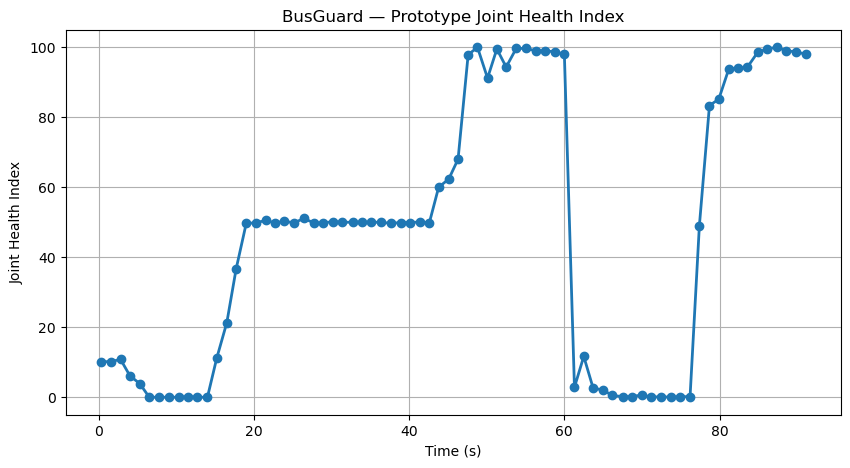

In [52]:
plt.figure(figsize=(10, 5))

plt.plot(
    df_hi["t"],
    df_hi["health_index"],
    marker="o",
    linewidth=2
)

plt.xlabel("Time (s)")
plt.ylabel("Joint Health Index")
plt.title("BusGuard — Prototype Joint Health Index")
plt.ylim(-5, 105)
plt.grid(True)

plt.show()

In [53]:
print("Out-of-fold accuracy:", round(accuracy, 3))
print("Out-of-fold weighted F1:", round(f1, 3))

Out-of-fold accuracy: 1.0
Out-of-fold weighted F1: 1.0
